# ¿Cómo sé si alguien leyó mi mensaje?
Programando qubits con Python · PyDay La Plata 2026 · Valentina Pértile de la Vega

Instalación: `pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib pylatexenc`. Todo corre en tu compu, sin internet. En Google Colab, ejecutá antes una celda con `%pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib pylatexenc`.

In [1]:
import random
from collections import Counter
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeBrisbane

perfecto = AerSimulator()                            # simulador ideal
ruidoso = AerSimulator.from_backend(FakeBrisbane())  # imita el ruido de una computadora real de IBM

def ejecutar(circuitos, shots=1000, backend=perfecto):
    resultado = backend.run(transpile(circuitos, backend), shots=shots).result()
    return resultado.get_counts()

## 1. Un qubit desde cero, con NumPy

In [2]:
class Qubit:
    def __init__(self):
        self.estado = np.array([1, 0], dtype=complex)   # empieza en |0⟩

    def x(self):
        self.estado = np.array([[0, 1], [1, 0]]) @ self.estado

    def h(self):
        self.estado = np.array([[1, 1], [1, -1]]) / np.sqrt(2) @ self.estado

    def medir(self):
        probs = np.abs(self.estado) ** 2
        resultado = np.random.choice([0, 1], p=probs)
        self.estado = np.eye(2)[resultado]              # leerlo lo cambia
        return int(resultado)

    def __repr__(self):
        a, b = np.round(self.estado.real, 3)
        return f"{a}|0⟩ + {b}|1⟩"

In [3]:
q = Qubit()
q.h()
q

0.707|0⟩ + 0.707|1⟩

In [4]:
print("Leo:", q.medir())
print("Ahora el qubit es:", q)
print("Lo leo 5 veces más:", [q.medir() for _ in range(5)])

Leo: 0
Ahora el qubit es: 1.0|0⟩ + 0.0|1⟩
Lo leo 5 veces más: [0, 0, 0, 0, 0]


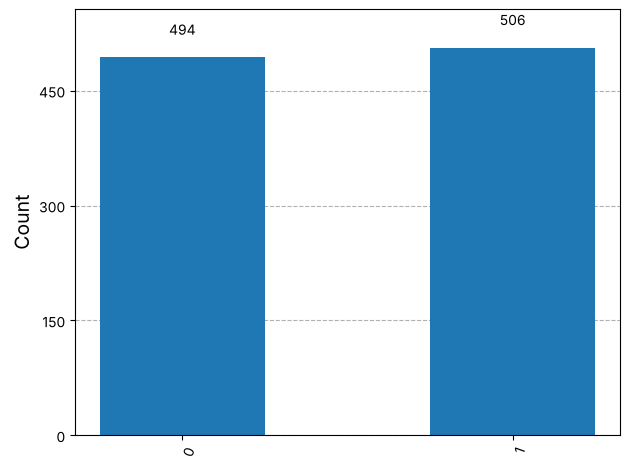

In [5]:
def tirar():
    q = Qubit()
    q.h()
    return q.medir()

plot_histogram(Counter(str(tirar()) for _ in range(1000)))

## 2. Dos bases, ahora con Qiskit
Alice escribe un 1 en la base H. Si Bob lee en la misma base, lo lee bien. Si lee en el otro, obtiene cualquier cosa.

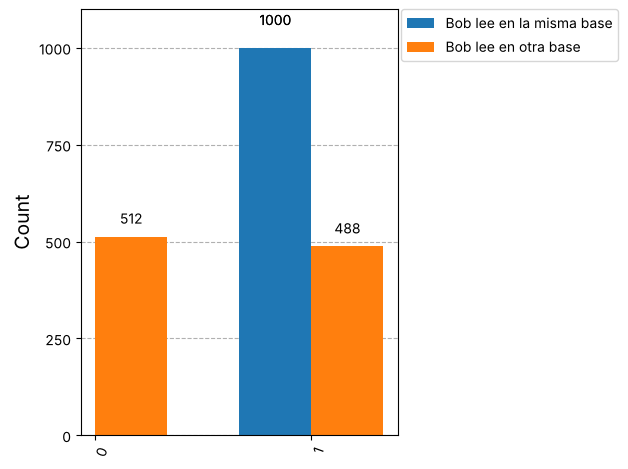

In [6]:
def mensaje(bit, base_alice, base_bob):
    qc = QuantumCircuit(1, 1)
    if bit == 1:
        qc.x(0)                # Alice escribe el bit
    if base_alice == "H":
        qc.h(0)                # ...en la base H
    if base_bob == "H":
        qc.h(0)                # Bob lee en la base H
    qc.measure(0, 0)
    return qc

plot_histogram([ejecutar(mensaje(1, "H", "H")), ejecutar(mensaje(1, "H", "normal"))],
               legend=["Bob lee en la misma base", "Bob lee en otra base"])

## 3. BB84: Alice le manda una clave a Bob

In [7]:
def bb84(n=400, espia=False, backend=perfecto):
    envios = []
    for _ in range(n):
        bit = random.randint(0, 1)
        alice, bob = random.choice(["normal", "H"]), random.choice(["normal", "H"])
        qc = QuantumCircuit(1, 1)
        if bit == 1: qc.x(0)
        if alice == "H": qc.h(0)
        if espia:                               # Eve lee el qubit en una base al azar...
            eve = random.choice(["normal", "H"])
            if eve == "H": qc.h(0)
            qc.measure(0, 0)
            if eve == "H": qc.h(0)              # ...y se lo reenvía a Bob
        if bob == "H": qc.h(0)
        qc.measure(0, 0)
        envios.append((bit, alice == bob, qc))

    leidos = ejecutar([qc for _, _, qc in envios], shots=1, backend=backend)
    # Alice y Bob comparan las bases en público y se quedan con los que coinciden
    clave = [(bit, int(next(iter(r)))) for (bit, coincide, _), r in zip(envios, leidos) if coincide]
    errores = sum(a != b for a, b in clave)

    print("Alice:", "".join(str(a) for a, _ in clave[:30]))
    print("Bob:  ", "".join(str(b) for _, b in clave[:30]))
    print("      ", "".join("^" if a != b else " " for a, b in clave[:30]))
    print(f"Errores: {errores} de {len(clave)} bits ({100 * errores / len(clave):.0f} %)")

bb84()

Alice: 011100100011000101010001100100
Bob:   011100100011000101010001100100
                                     
Errores: 0 de 203 bits (0 %)


## 4. Ahora Eve espía

In [8]:
bb84(espia=True)

Alice: 000111011111011110100100001011
Bob:   000001011111011010100001101011
          ^^          ^     ^ ^^     
Errores: 49 de 211 bits (23 %)


## Bonus para casa: sin espía, pero con el ruido de una computadora real

In [9]:
bb84(backend=ruidoso)

Alice: 000101011100000000001101000100
Bob:   000101011100000000001101000100
                                     
Errores: 1 de 192 bits (1 %)
